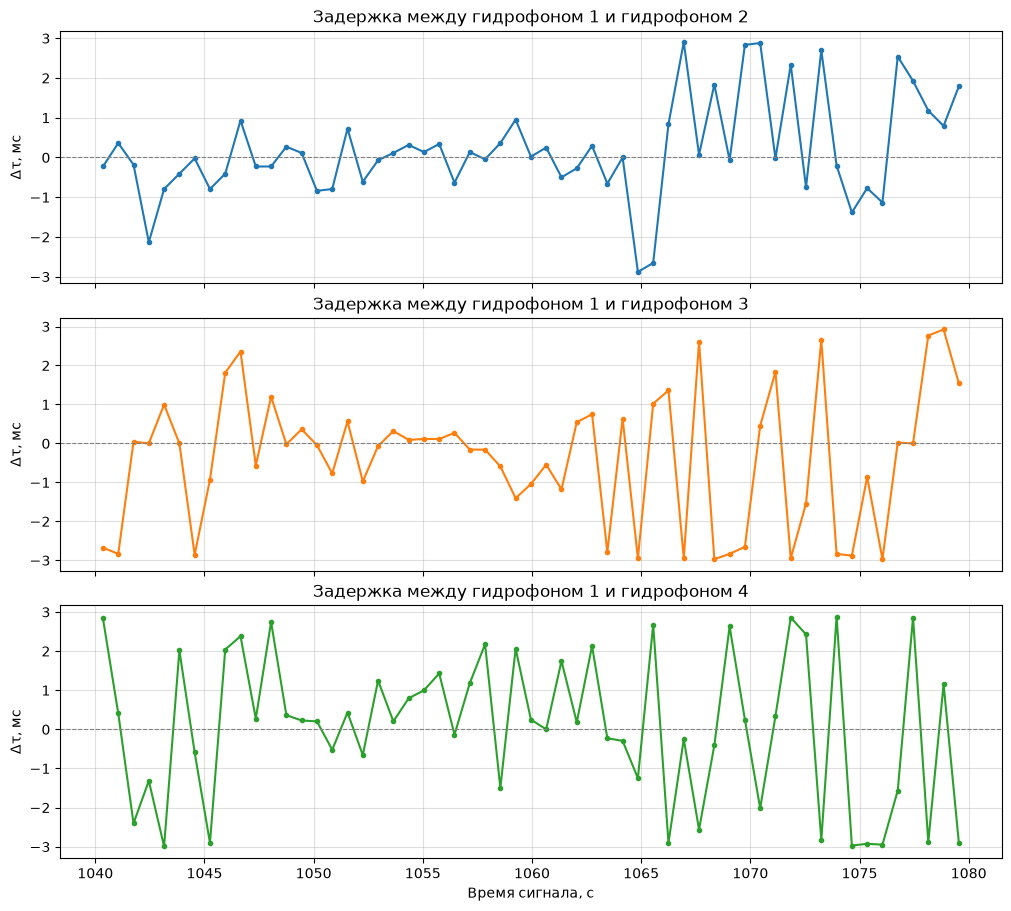

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt


WAV_PATHS = [
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S1.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S2.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S3.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S4.wav'  
]

# Координаты гидрофонов пирамидки (X, Y, Z в метрах)
HYDROPHONE_COORDS = np.array([
    [ 0.21435,  0.39137,  0.76355],  # Гидрофон 0 (Канал 1)
    [-0.07129,  0.23798,  1.10660],  # Гидрофон 1 (Канал 2)
    [ 0.12668,  0.86548,  0.81975],  # Гидрофон 2 (Канал 3)
    [ 0.33862,  0.60252,  1.31124]   # Гидрофон 3 (Канал 4)
])
# Скорость звука в воде, м/с
SOUND_SPEED = 1500.0

# Выбранный диапазон времени для анализа (в секундах)
T_START = 1040.0                  
T_END = 1080.0                    

# Параметры нарезки
WINDOW_SEC = 0.7                 
OVERLAP = 0.0                    

# Диапазон частот (полосовой фильтр), Гц
F_LOW = 2500.0                    
F_HIGH = 2650.0                  

# Ограничение оси задержек на графике (в миллисекундах)
MAX_LAG_MS = 3.0                 



def load_single_channel(wav_path):
    """Загружает моно-WAV, переводит во float."""
    fs, data = wavfile.read(wav_path)
    if data.ndim > 1:
        data = data[:, 0]
    if np.issubdtype(data.dtype, np.integer):
        data = data.astype(np.float64) / np.iinfo(data.dtype).max
    else:
        data = data.astype(np.float64)
    return fs, data

def align_lengths_with_zeros(sig1, sig2, pad_left=False):
    len1, len2 = len(sig1), len(sig2)
    if len1 == len2:
        return sig1, sig2
    diff = abs(len1 - len2)
    pad_width = (diff, 0) if pad_left else (0, diff)
    if len1 < len2:
        sig1 = np.pad(sig1, pad_width, mode='constant', constant_values=0.0)
    else:
        sig2 = np.pad(sig2, pad_width, mode='constant', constant_values=0.0)
    return sig1, sig2

def bandpass_filter(sig, fs, f_low, f_high, order=4):
    nyq = 0.5 * fs
    sos = butter(order, [f_low / nyq, f_high / nyq], btype='band', output='sos')
    return sosfiltfilt(sos, sig)

def spectral_xcorr(x, y):
    x, y = align_lengths_with_zeros(x, y, pad_left=False)
    n = len(x)
    x = x - np.mean(x)
    y = y - np.mean(y)
    n_fft = 1 << (2 * n - 1).bit_length()
    
    spec_x = np.fft.rfft(x, n=n_fft)
    spec_y = np.fft.rfft(y, n=n_fft)
    
    cross_spectrum = spec_x * np.conj(spec_y)
    ccf_raw = np.fft.irfft(cross_spectrum, n=n_fft)
    
    ccf_linear = np.concatenate((ccf_raw[-(n - 1):], ccf_raw[:n]))
    norm = np.sqrt(np.sum(x**2) * np.sum(y**2))
    if norm > 0:
        ccf_linear /= norm
    else:
        ccf_linear = np.zeros_like(ccf_linear)
        
    lags = np.arange(-(n - 1), n)
    return ccf_linear, lags

# def calculate_theoretical_delays(source_dir, coords, c=1500.0):
#     """
#     Вычисляем теоретические задержки (в секундах) прихода плоской волны на гидрофоны относительно первого гидрофона (coords[0]).
#     """
#     source_dir = np.array(source_dir, dtype=np.float64)
#     source_dir /= np.linalg.norm(source_dir)
    
#     # Разности радиус-векторов относительно гидрофона 0
#     dr = coords - coords[0]  # форма (N, 3)
    

#     # Время задержки t = (dr * dir) / c
#     delays = np.dot(dr, source_dir) / c
#     return delays


signals = []
fs_base = None

for i, path in enumerate(WAV_PATHS):
    fs, raw_sig = load_single_channel(path)
    if fs_base is None:
        fs_base = fs
    elif fs != fs_base:
        raise ValueError(f"Частота дискретизации канала {i+1} не совпадает!")
    signals.append(raw_sig)

fs = fs_base

# Выравниваем длины всех 4 каналов
max_len = max(len(s) for s in signals)
signals = [np.pad(s, (0, max_len - len(s)), mode='constant') for s in signals]

# Фильтрация
pad_sec = 0.5
idx_start_pad = max(0, int((T_START - pad_sec) * fs))
idx_end_pad = min(max_len, int((T_END + pad_sec) * fs))

filtered_signals = []
for sig in signals:
    filt = bandpass_filter(sig[idx_start_pad:idx_end_pad], fs, F_LOW, F_HIGH)
    trim_start = int(T_START * fs) - idx_start_pad
    trim_end = trim_start + int((T_END - T_START) * fs)
    
    s_cut = filt[trim_start:trim_end]
    target_len = int((T_END - T_START) * fs)
    if len(s_cut) < target_len:
        s_cut = np.pad(s_cut, (0, target_len - len(s_cut)), mode='constant')
    filtered_signals.append(s_cut)


# 4. РАСЧЕТ ВКФ МЕЖДУ КАНАЛОМ 1 И ОСТАЛЬНЫМИ (1-2, 1-3, 1-4)

win_samples = int(round(WINDOW_SEC * fs))
step_samples = int(round(win_samples * (1.0 - OVERLAP)))

results_delta = {2: [], 3: [], 4: []} # пары относительно 1-го канала (индексы 1, 2, 3)
window_times = []

for start in range(0, len(filtered_signals[0]) - win_samples + 1, step_samples):
    w1 = filtered_signals[0][start : start + win_samples]
    t_center = T_START + (start + win_samples / 2) / fs
    window_times.append(t_center)
    
    for ch_idx in [1, 2, 3]:
        w_curr = filtered_signals[ch_idx][start : start + win_samples]
        ccf, lags = spectral_xcorr(w1, w_curr)
        
        lags_ms = (lags / fs) * 1000.0
        lag_mask = (lags_ms >= -MAX_LAG_MS) & (lags_ms <= MAX_LAG_MS)
        lags_ms_zoom = lags_ms[lag_mask]
        ccf_zoom = ccf[lag_mask]
        
        best_lag_ms = lags_ms_zoom[np.argmax(np.abs(ccf_zoom))]
        results_delta[ch_idx + 1].append(best_lag_ms)


fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)

for idx, ch_target in enumerate([2, 3, 4]):
    axes[idx].plot(window_times, results_delta[ch_target], '.-', color=f'C{idx}')
    axes[idx].set_title(f'Задержка между гидрофоном 1 и гидрофоном {ch_target}')
    axes[idx].set_ylabel('Δτ, мс')
    axes[idx].grid(True, alpha=0.4)
    axes[idx].axhline(0, color='gray', linestyle='--', linewidth=0.8)

axes[-1].set_xlabel("Время сигнала, с")
plt.show()

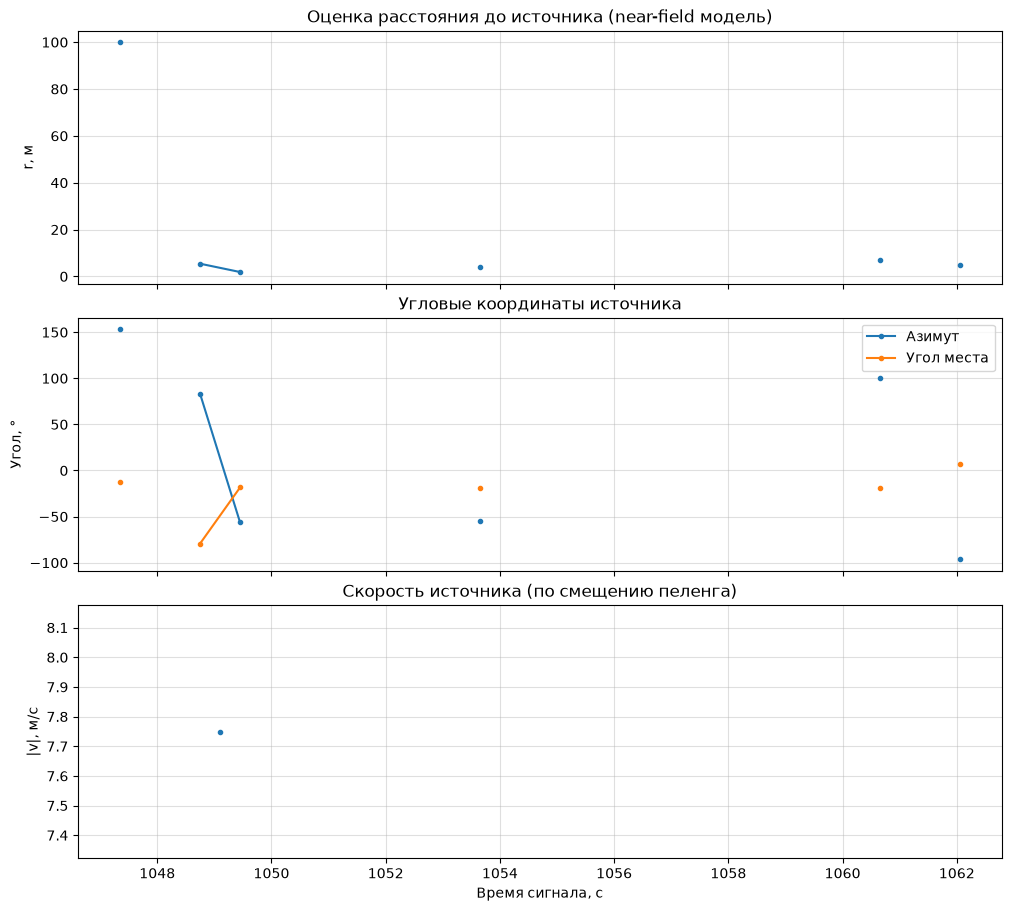

In [3]:
# ... всё, что было до цикла по окнам, оставляем без изменений ...

# ================= ПЕЛЕНГАЦИЯ ИСТОЧНИКА =================
from scipy.optimize import minimize_scalar

def solve_direction(coords, tdoas, c=1500.0):
    """
    tdoas: [t_1-t_0, t_2-t_0, t_3-t_0] в секундах.
    Возвращает единичный вектор u — направление распространения волны (источник → массив).
    Направление на источник: -u.
    """
    A = (coords[1:] - coords[0]) / c
    u, *_ = np.linalg.lstsq(A, tdoas, rcond=None)
    n = np.linalg.norm(u)
    return u / n if n > 0 else np.full(3, np.nan)

def estimate_range(coords, u_wave, tdoas, c=1500.0, r_min=1.0, r_max=100.0):
    """Оценка расстояния до источника (near-field, сферический фронт)."""
    def residual(r):
        s = coords[0] - r * u_wave      # источник в направлении -u_wave
        res = 0.0
        for k in range(1, len(coords)):
            d_k = np.linalg.norm(s - coords[k])
            d_0 = np.linalg.norm(s - coords[0])
            res += ((d_k - d_0) / c - tdoas[k - 1]) ** 2
        return res
    return minimize_scalar(residual, bounds=(r_min, r_max), method='bounded').x

# Пересобираем TDOA по окнам (в секундах)
n_windows = len(window_times)
tdoas_arr = np.array([
    [results_delta[ch][i] / 1000.0 for ch in (2, 3, 4)]
    for i in range(n_windows)
])

# Максимально физически возможный TDOA при данной геометрии
max_baseline = max(np.linalg.norm(HYDROPHONE_COORDS[k] - HYDROPHONE_COORDS[0])
                   for k in range(1, len(HYDROPHONE_COORDS)))
max_tdoa = max_baseline / SOUND_SPEED

directions = np.full((n_windows, 3), np.nan)
ranges     = np.full(n_windows, np.nan)
positions  = np.full((n_windows, 3), np.nan)

for i in range(n_windows):
    # отбрасываем физически невозможные измерения
    if np.any(~np.isfinite(tdoas_arr[i])) or np.any(np.abs(tdoas_arr[i]) > 1.5 * max_tdoa):
        continue
    u_wave = solve_direction(HYDROPHONE_COORDS, tdoas_arr[i])
    if not np.all(np.isfinite(u_wave)):
        continue
    r = estimate_range(HYDROPHONE_COORDS, u_wave, tdoas_arr[i])
    s_dir = -u_wave
    directions[i] = s_dir
    ranges[i]     = r
    positions[i]  = HYDROPHONE_COORDS[0] + r * s_dir

# Углы
azimuths   = np.degrees(np.arctan2(directions[:, 1], directions[:, 0]))
elevations = np.degrees(np.arcsin(np.clip(directions[:, 2], -1.0, 1.0)))

# Скорость (конечные разности оценок положения)
window_times_arr = np.asarray(window_times, dtype=float)
dt = np.diff(window_times_arr)
velocities = np.diff(positions, axis=0) / dt[:, None]
speeds     = np.linalg.norm(velocities, axis=1)
vel_times  = 0.5 * (window_times_arr[:-1] + window_times_arr[1:])

# ================= ГРАФИКИ =================
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)

axes[0].plot(window_times_arr, ranges, '.-')
axes[0].set_title('Оценка расстояния до источника (near-field модель)')
axes[0].set_ylabel('r, м')
axes[0].grid(True, alpha=0.4)

axes[1].plot(window_times_arr, azimuths,   '.-', label='Азимут')
axes[1].plot(window_times_arr, elevations, '.-', label='Угол места')
axes[1].set_title('Угловые координаты источника')
axes[1].set_ylabel('Угол, °')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

axes[2].plot(vel_times, speeds, '.-')
axes[2].set_title('Скорость источника (по смещению пеленга)')
axes[2].set_ylabel('|v|, м/с')
axes[2].set_xlabel('Время сигнала, с')
axes[2].grid(True, alpha=0.4)

plt.show()

Физический предел задержки: ±0.600 мс. Окно поиска установлено: ±0.600 мс


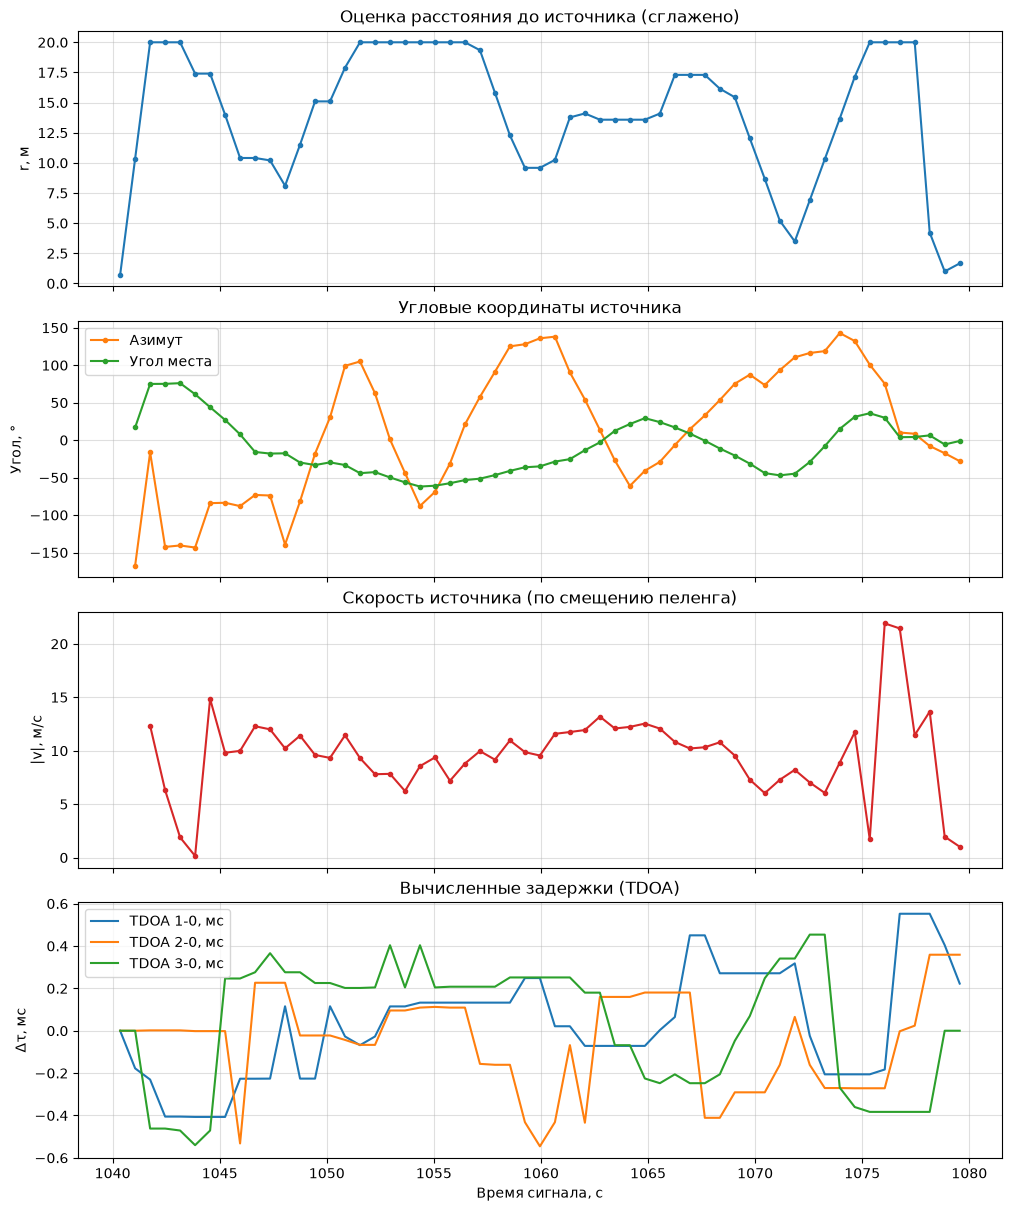

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, medfilt
from scipy.optimize import minimize_scalar
from scipy.interpolate import interp1d

# ... (ВЕРХНЯЯ ЧАСТЬ СКРИПТА С ЗАГРУЗКОЙ WAV, ФИЛЬТРАЦИЕЙ И HYDROPHONE_COORDS ОСТАЕТСЯ БЕЗ ИЗМЕНЕНИЙ) ...

# --- НОВЫЕ ПАРАМЕТРЫ ---
# Физический предел задержки для данной геометрии (в мс)
max_baseline = max(np.linalg.norm(HYDROPHONE_COORDS[k] - HYDROPHONE_COORDS[0]) for k in range(1, 4))
MAX_LAG_MS = (max_baseline / SOUND_SPEED) * 1000.0 * 1.5  # Берем с запасом 50%
print(f"Физический предел задержки: ±{MAX_LAG_MS:.3f} мс. Окно поиска установлено: ±{MAX_LAG_MS:.3f} мс")

# ================= РАСЧЕТ TDOA =================
win_samples = int(round(WINDOW_SEC * fs))
step_samples = int(round(win_samples * (1.0 - OVERLAP)))

results_delta = {2: [], 3: [], 4: []}
window_times = []

def get_sub_sample_peak(ccf_zoom, lags_ms_zoom):
    """Параболическая интерполяция для поиска точного пика между отсчетами."""
    peak_idx = np.argmax(np.abs(ccf_zoom))
    if 0 < peak_idx < len(ccf_zoom) - 1:
        y0 = np.abs(ccf_zoom[peak_idx - 1])
        y1 = np.abs(ccf_zoom[peak_idx])
        y2 = np.abs(ccf_zoom[peak_idx + 1])
        denom = (y0 - 2*y1 + y2)
        if denom != 0:
            delta = 0.5 * (y0 - y2) / denom
            dt_ms = lags_ms_zoom[1] - lags_ms_zoom[0]
            return lags_ms_zoom[peak_idx] + delta * dt_ms
    return lags_ms_zoom[peak_idx]

for start in range(0, len(filtered_signals[0]) - win_samples + 1, step_samples):
    w1 = filtered_signals[0][start : start + win_samples]
    t_center = T_START + (start + win_samples / 2) / fs
    window_times.append(t_center)
    
    for ch_idx in [1, 2, 3]:
        w_curr = filtered_signals[ch_idx][start : start + win_samples]
        ccf, lags = spectral_xcorr(w1, w_curr)
        
        lags_ms = (lags / fs) * 1000.0
        lag_mask = (lags_ms >= -MAX_LAG_MS) & (lags_ms <= MAX_LAG_MS)
        lags_ms_zoom = lags_ms[lag_mask]
        ccf_zoom = ccf[lag_mask]
        
        # Используем субдискретизацию
        best_lag_ms = get_sub_sample_peak(ccf_zoom, lags_ms_zoom)
        results_delta[ch_idx + 1].append(best_lag_ms)

# Медианная фильтрация для удаления выбросов ВКФ
for ch in [2, 3, 4]:
    results_delta[ch] = medfilt(results_delta[ch], kernel_size=5)

# ================= ПЕЛЕНГАЦИЯ ИСТОЧНИКА =================
def solve_direction(coords, tdoas, c=1500.0):
    A = (coords[1:] - coords[0]) / c
    u, *_ = np.linalg.lstsq(A, tdoas, rcond=None)
    n = np.linalg.norm(u)
    return u / n if n > 0 else np.full(3, np.nan)

def estimate_range(coords, u_wave, tdoas, c=1500.0, r_min=1.0, r_max=20.0):
    def residual(r):
        s = coords[0] - r * u_wave
        res = 0.0
        for k in range(1, len(coords)):
            d_k = np.linalg.norm(s - coords[k])
            d_0 = np.linalg.norm(s - coords[0])
            res += ((d_k - d_0) / c - tdoas[k - 1]) ** 2
        return res
    return minimize_scalar(residual, bounds=(r_min, r_max), method='bounded').x

n_windows = len(window_times)
tdoas_arr = np.array([
    [results_delta[ch][i] / 1000.0 for ch in (2, 3, 4)]
    for i in range(n_windows)
])

directions = np.full((n_windows, 3), np.nan)
ranges     = np.full(n_windows, np.nan)
positions  = np.full((n_windows, 3), np.nan)

for i in range(n_windows):
    if np.any(~np.isfinite(tdoas_arr[i])):
        continue
    u_wave = solve_direction(HYDROPHONE_COORDS, tdoas_arr[i])
    if not np.all(np.isfinite(u_wave)):
        continue
    
    # Ограничиваем макс. дистанцию, так как near-field на малой базе шумит
    r = estimate_range(HYDROPHONE_COORDS, u_wave, tdoas_arr[i], r_max=20.0)
    s_dir = -u_wave
    directions[i] = s_dir
    ranges[i]     = r
    positions[i]  = HYDROPHONE_COORDS[0] + r * s_dir

# Заполнение пропусков (NaN) для непрерывности графиков
valid_idx = ~np.isnan(ranges)
if np.sum(valid_idx) > 2:
    f_range = interp1d(np.array(window_times)[valid_idx], ranges[valid_idx], bounds_error=False, fill_value="extrapolate")
    ranges = f_range(window_times)
    
    # Сглаживание траектории (скользящее среднее)
    def smooth(y, box_pts=5):
        box = np.ones(box_pts)/box_pts
        y_smooth = np.convolve(y, box, mode='same')
        # Края обрабатываем отдельно, чтобы не было провалов
        y_smooth[:box_pts] = y[:box_pts]
        y_smooth[-box_pts:] = y[-box_pts:]
        return y_smooth

    ranges = smooth(ranges, 5)

    # Пересчет углов по сглаженной траектории
    azimuths   = np.degrees(np.arctan2(directions[:, 1], directions[:, 0]))
    elevations = np.degrees(np.arcsin(np.clip(directions[:, 2], -1.0, 1.0)))
    
    azimuths   = smooth(azimuths, 5)
    elevations = smooth(elevations, 5)

    # ================= СКОРОСТЬ =================
    # Вычисляем скорость через np.gradient (работает даже с неравномерным шагом)
    t_arr = np.array(window_times)
    # np.gradient требует монотонного времени
    vx = np.gradient(positions[:, 0], t_arr)
    vy = np.gradient(positions[:, 1], t_arr)
    vz = np.gradient(positions[:, 2], t_arr)
    
    speeds = np.sqrt(vx**2 + vy**2 + vz**2)
    speeds = smooth(speeds, 7) # Сильно сглаживаем скорость

    # ================= ГРАФИКИ =================
    fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True, constrained_layout=True)

    axes[0].plot(window_times, ranges, '.-', color='C0')
    axes[0].set_title('Оценка расстояния до источника (сглажено)')
    axes[0].set_ylabel('r, м')
    axes[0].grid(True, alpha=0.4)

    axes[1].plot(window_times, azimuths,   '.-', label='Азимут', color='C1')
    axes[1].plot(window_times, elevations, '.-', label='Угол места', color='C2')
    axes[1].set_title('Угловые координаты источника')
    axes[1].set_ylabel('Угол, °')
    axes[1].legend()
    axes[1].grid(True, alpha=0.4)

    axes[2].plot(window_times, speeds, '.-', color='C3')
    axes[2].set_title('Скорость источника (по смещению пеленга)')
    axes[2].set_ylabel('|v|, м/с')
    axes[2].grid(True, alpha=0.4)

    axes[3].plot(window_times, tdoas_arr[:, 0]*1000, label='TDOA 1-0, мс')
    axes[3].plot(window_times, tdoas_arr[:, 1]*1000, label='TDOA 2-0, мс')
    axes[3].plot(window_times, tdoas_arr[:, 2]*1000, label='TDOA 3-0, мс')
    axes[3].set_title('Вычисленные задержки (TDOA)')
    axes[3].set_ylabel('Δτ, мс')
    axes[3].set_xlabel('Время сигнала, с')
    axes[3].legend()
    axes[3].grid(True, alpha=0.4)

    plt.show()
else:
    print("Недостаточно валидных точек для построения графиков.")

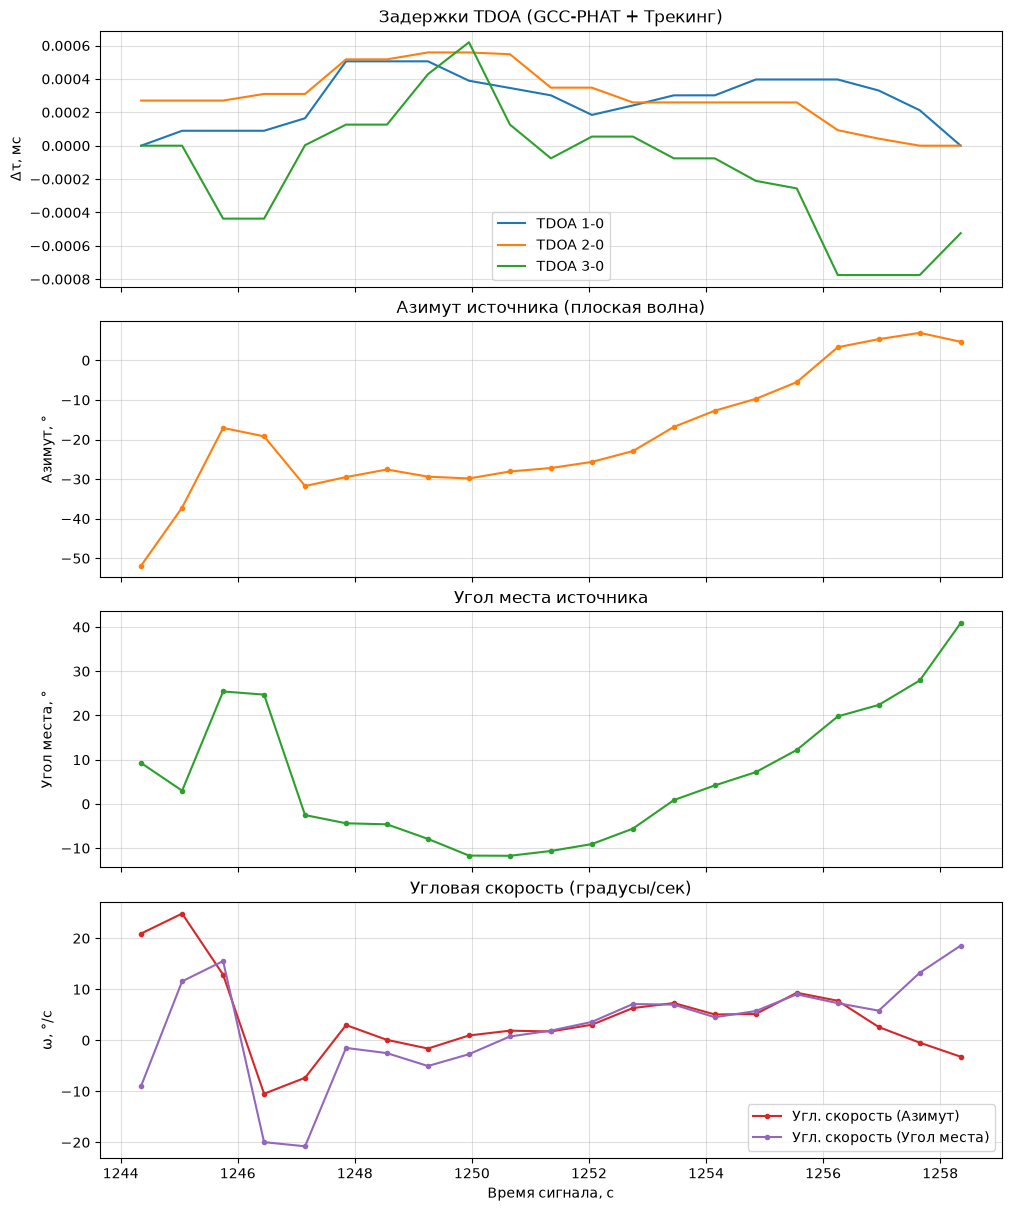

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, medfilt
from scipy.interpolate import interp1d

# --- ВАШИ ИСХОДНЫЕ ДАННЫЕ ---
WAV_PATHS = [
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S1.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S2.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S3.wav',
    '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S4.wav'  
]

HYDROPHONE_COORDS = np.array([
    [ 0.21435,  0.39137,  0.76355], 
    [-0.07129,  0.23798,  1.10660], 
    [ 0.12668,  0.86548,  0.81975], 
    [ 0.33862,  0.60252,  1.31124]  
])
SOUND_SPEED = 1500.0

T_START = 1244.0                  
T_END = 1259.0                    
WINDOW_SEC = 0.7                 
OVERLAP = 0.0                    
F_LOW = 600.0                    
F_HIGH = 1200.0                  

# --- НОВЫЕ ПАРАМЕТРЫ ДЛЯ ТРЕКИНГА ---
max_baseline = max(np.linalg.norm(HYDROPHONE_COORDS[k] - HYDROPHONE_COORDS[0]) for k in range(1, 4))
MAX_LAG_MS = (max_baseline / SOUND_SPEED) * 1000.0 * 1.2 # Физический предел
TRACK_RADIUS_MS = 0.15 # Радиус поиска вокруг предыдущего пика (в мс)

def load_single_channel(wav_path):
    fs, data = wavfile.read(wav_path)
    if data.ndim > 1: data = data[:, 0]
    if np.issubdtype(data.dtype, np.integer):
        data = data.astype(np.float64) / np.iinfo(data.dtype).max
    else:
        data = data.astype(np.float64)
    return fs, data

def align_lengths_with_zeros(sig1, sig2, pad_left=False):
    len1, len2 = len(sig1), len(sig2)
    if len1 == len2: return sig1, sig2
    diff = abs(len1 - len2)
    pad_width = (diff, 0) if pad_left else (0, diff)
    if len1 < len2: sig1 = np.pad(sig1, pad_width, mode='constant')
    else: sig2 = np.pad(sig2, pad_width, mode='constant')
    return sig1, sig2

def bandpass_filter(sig, fs, f_low, f_high, order=4):
    nyq = 0.5 * fs
    sos = butter(order, [f_low / nyq, f_high / nyq], btype='band', output='sos')
    return sosfiltfilt(sos, sig)

def gcc_phat(x, y):
    """GCC-PHAT: Заостряет главный пик и давит эхо (реверберацию)."""
    x, y = align_lengths_with_zeros(x, y, pad_left=False)
    n = len(x)
    x = x - np.mean(x)
    y = y - np.mean(y)
    n_fft = 1 << (2 * n - 1).bit_length()
    
    spec_x = np.fft.rfft(x, n=n_fft)
    spec_y = np.fft.rfft(y, n=n_fft)
    
    cross_spectrum = spec_x * np.conj(spec_y)
    # ФАЗОВЫЙ ТРАНСФОРМ (суть PHAT)
    cross_spectrum /= (np.abs(cross_spectrum) + 1e-10) 
    
    ccf_raw = np.fft.irfft(cross_spectrum, n=n_fft)
    ccf_linear = np.concatenate((ccf_raw[-(n - 1):], ccf_raw[:n]))
    
    lags = np.arange(-(n - 1), n)
    return ccf_linear, lags

def get_sub_sample_peak(ccf_zoom, lags_ms_zoom):
    """Параболическая интерполяция для точности до микросекунд."""
    peak_idx = np.argmax(np.abs(ccf_zoom))
    if 0 < peak_idx < len(ccf_zoom) - 1:
        y0, y1, y2 = np.abs(ccf_zoom[peak_idx-1:peak_idx+2])
        denom = (y0 - 2*y1 + y2)
        if denom != 0:
            delta = 0.5 * (y0 - y2) / denom
            dt_ms = lags_ms_zoom[1] - lags_ms_zoom[0]
            return lags_ms_zoom[peak_idx] + delta * dt_ms
    return lags_ms_zoom[peak_idx]

# ================= ЗАГРУЗКА И ФИЛЬТРАЦИЯ =================
signals = []
fs_base = None
for path in WAV_PATHS:
    fs, raw_sig = load_single_channel(path)
    if fs_base is None: fs_base = fs
    signals.append(raw_sig)
fs = fs_base

max_len = max(len(s) for s in signals)
signals = [np.pad(s, (0, max_len - len(s)), mode='constant') for s in signals]

pad_sec = 0.5
idx_start_pad = max(0, int((T_START - pad_sec) * fs))
idx_end_pad = min(max_len, int((T_END + pad_sec) * fs))

filtered_signals = []
for sig in signals:
    filt = bandpass_filter(sig[idx_start_pad:idx_end_pad], fs, F_LOW, F_HIGH)
    trim_start = int(T_START * fs) - idx_start_pad
    trim_end = trim_start + int((T_END - T_START) * fs)
    s_cut = filt[trim_start:trim_end]
    target_len = int((T_END - T_START) * fs)
    if len(s_cut) < target_len: s_cut = np.pad(s_cut, (0, target_len - len(s_cut)), mode='constant')
    filtered_signals.append(s_cut)

# ================= ТРЕКИНГ TDOA =================
win_samples = int(round(WINDOW_SEC * fs))
step_samples = int(round(win_samples * (1.0 - OVERLAP)))

results_delta = {2: [], 3: [], 4: []}
window_times = []
prev_lags = {2: 0.0, 3: 0.0, 4: 0.0} # Инициализация трекера (нулевые задержки)

for start in range(0, len(filtered_signals[0]) - win_samples + 1, step_samples):
    w1 = filtered_signals[0][start : start + win_samples]
    t_center = T_START + (start + win_samples / 2) / fs
    window_times.append(t_center)
    
    for ch_idx in [1, 2, 3]:
        ch_key = ch_idx + 1
        w_curr = filtered_signals[ch_idx][start : start + win_samples]
        ccf, lags = gcc_phat(w1, w_curr)
        lags_ms = (lags / fs) * 1000.0
        
        # ЛОГИКА ТРЕКИНГА: ищем только рядом с предыдущим пиком
        if len(window_times) == 1:
            # Первое окно - глобальный поиск
            search_radius = MAX_LAG_MS
        else:
            search_radius = TRACK_RADIUS_MS
            
        center_lag = prev_lags[ch_key]
        lag_mask = (lags_ms >= center_lag - search_radius) & (lags_ms <= center_lag + search_radius)
        
        # Если пик потерян (окно пустое), делаем глобальный поиск
        if not np.any(lag_mask):
            lag_mask = (lags_ms >= -MAX_LAG_MS) & (lags_ms <= MAX_LAG_MS)
            
        lags_ms_zoom = lags_ms[lag_mask]
        ccf_zoom = ccf[lag_mask]
        
        best_lag_ms = get_sub_sample_peak(ccf_zoom, lags_ms_zoom)
        results_delta[ch_key].append(best_lag_ms)
        prev_lags[ch_key] = best_lag_ms # Обновляем трекер

# Медианная фильтрация для TDOA
for ch in [2, 3, 4]:
    results_delta[ch] = medfilt(results_delta[ch], kernel_size=5)

# ================= ПЕЛЕНГАЦИЯ (ПЛОСКАЯ ВОЛНА) =================
def solve_direction(coords, tdoas, c=1500.0):
    A = (coords[1:] - coords[0]) / c
    u, *_ = np.linalg.lstsq(A, tdoas, rcond=None)
    n = np.linalg.norm(u)
    return u / n if n > 0 else np.full(3, np.nan)

n_windows = len(window_times)
tdoas_arr = np.array([[results_delta[ch][i] / 1000.0 for ch in (2, 3, 4)] for i in range(n_windows)])

azimuths = np.full(n_windows, np.nan)
elevations = np.full(n_windows, np.nan)

for i in range(n_windows):
    u_wave = solve_direction(HYDROPHONE_COORDS, tdoas_arr[i])
    if np.all(np.isfinite(u_wave)):
        s_dir = -u_wave # Вектор НА источник
        azimuths[i] = np.degrees(np.arctan2(s_dir[1], s_dir[0]))
        elevations[i] = np.degrees(np.arcsin(np.clip(s_dir[2], -1.0, 1.0)))

# Сглаживание и разворачивание углов (убираем скачки 180 -> -180)
t_arr = np.array(window_times)
azimuths_unwrapped = np.degrees(np.unwrap(np.radians(azimuths)))
elevations_unwrapped = np.degrees(np.unwrap(np.radians(elevations)))

def smooth(y, box_pts=7):
    """Скользящее среднее с сохранением границ."""
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    pad = box_pts // 2
    y_smooth[:pad] = y[:pad]
    y_smooth[-pad:] = y[-pad:]
    return y_smooth

az_smooth = smooth(azimuths_unwrapped, 9)
el_smooth = smooth(elevations_unwrapped, 9)

# ================= УГЛОВАЯ СКОРОСТЬ =================
az_velocity = np.gradient(az_smooth, t_arr)
el_velocity = np.gradient(el_smooth, t_arr)

# ================= ГРАФИКИ =================
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True, constrained_layout=True)

axes[0].plot(t_arr, tdoas_arr[:, 0]*1000, label='TDOA 1-0')
axes[0].plot(t_arr, tdoas_arr[:, 1]*1000, label='TDOA 2-0')
axes[0].plot(t_arr, tdoas_arr[:, 2]*1000, label='TDOA 3-0')
axes[0].set_title('Задержки TDOA (GCC-PHAT + Трекинг)')
axes[0].set_ylabel('Δτ, мс')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(t_arr, az_smooth, '.-', label='Азимут', color='C1')
axes[1].set_title('Азимут источника (плоская волна)')
axes[1].set_ylabel('Азимут, °')
axes[1].grid(True, alpha=0.4)

axes[2].plot(t_arr, el_smooth, '.-', label='Угол места', color='C2')
axes[2].set_title('Угол места источника')
axes[2].set_ylabel('Угол места, °')
axes[2].grid(True, alpha=0.4)

axes[3].plot(t_arr, az_velocity, '.-', label='Угл. скорость (Азимут)', color='C3')
axes[3].plot(t_arr, el_velocity, '.-', label='Угл. скорость (Угол места)', color='C4')
axes[3].set_title('Угловая скорость (градусы/сек)')
axes[3].set_ylabel('ω, °/с')
axes[3].set_xlabel('Время сигнала, с')
axes[3].legend()
axes[3].grid(True, alpha=0.4)

plt.show()

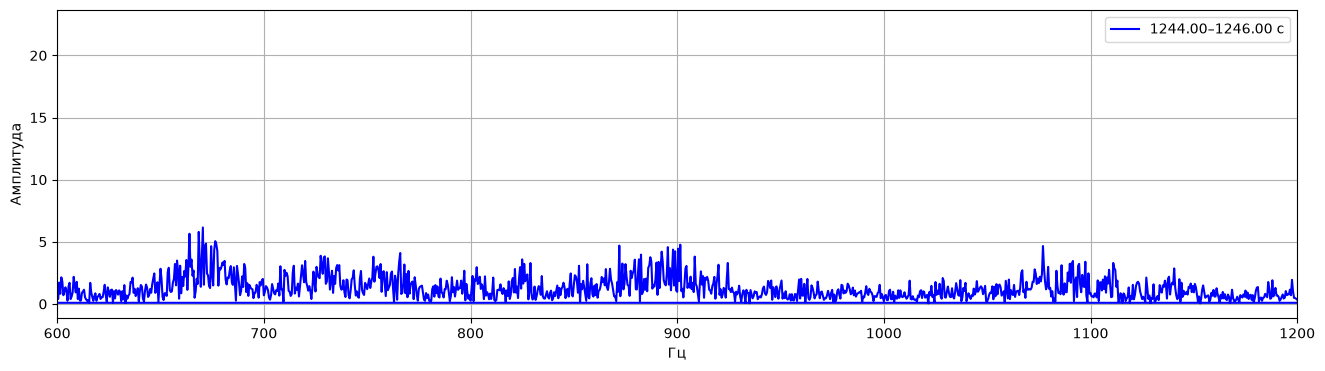

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq


def slice_signal_by_time(sig, fs, t_start, t_end, remove_dc=False, pad_zeros=False):
    """Вырезает фрагмент сигнала sig в интервале [t_start, t_end] (в секундах)."""
    if t_end <= t_start:
        raise ValueError("t_end должен быть больше t_start.")

    sig = np.asarray(sig, dtype=np.float64)
    i0 = max(0, int(round(t_start * fs)))
    i1_raw = int(round(t_end * fs))
    i1 = min(len(sig), i1_raw)

    if i1 <= i0 and not pad_zeros:
        raise ValueError("Указанный интервал не пересекается с длиной сигнала.")

    seg = sig[i0:i1].copy()

    if pad_zeros and i1_raw > len(sig):
        target_len = max(0, i1_raw - i0)
        if len(seg) < target_len:
            seg = np.pad(seg, (0, target_len - len(seg)), mode="constant")

    if remove_dc and len(seg) > 0:
        seg = seg - np.mean(seg)

    return seg


def plot_segment_spectrum(raw_signal, fs, t_start, t_end, f_min = 0, f_max=500.0, label=None):
    """Вырезает отрезок [t_start, t_end] из raw_signal и строит амплитудный спектр."""
    signal = slice_signal_by_time(raw_signal, fs, t_start, t_end)
    t = np.arange(len(signal)) / fs
    f = fftfreq(len(signal), 1.0 / fs)

    plot_label = label if label is not None else f"{t_start:.2f}–{t_end:.2f} с"

    plt.figure(figsize=(16, 4))
    plt.plot(f, np.abs(fft(signal)), color="blue", label=plot_label)
    plt.legend()
    plt.xlabel("Гц")
    plt.ylabel("Амплитуда")
    plt.grid(True)
    plt.xlim(f_min, f_max)
    plt.show()


# ==========================================
# ЗАПУСК: ЗАДАЙТЕ СИГНАЛ И ГРАНИЦЫ ОТРЕЗКА
# ==========================================
t_start = 1244.0
t_end = 1246.0

# Подставьте ваш сигнал (например, data_120cm или signals[0]) и частоту fs
plot_segment_spectrum(signals[0], fs, t_start, t_end, f_min = 600, f_max = 1200.0)

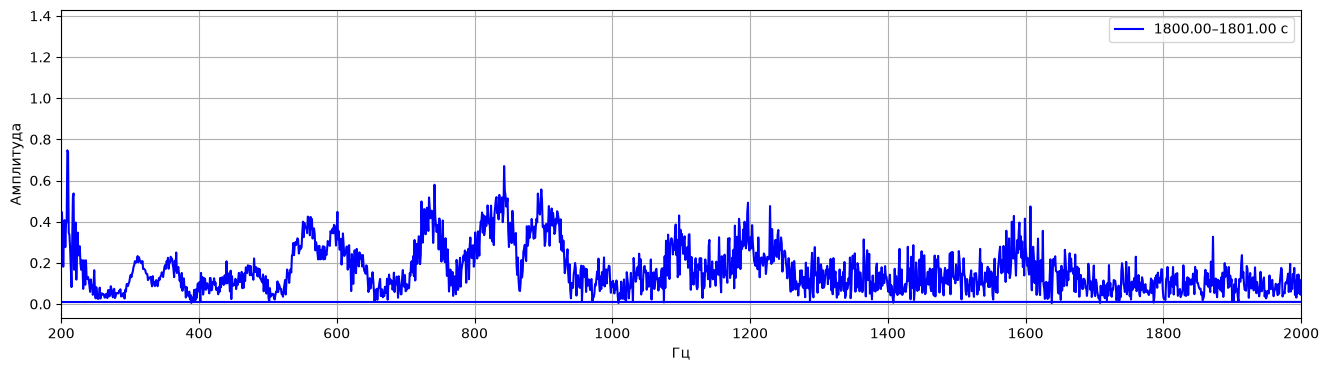

In [14]:
t_start = 1800.0
t_end = 1801.0

# Подставьте ваш сигнал (например, data_120cm или signals[0]) и частоту fs
plot_segment_spectrum(signals[0], fs, t_start, t_end, f_min = 200, f_max = 2000.0)

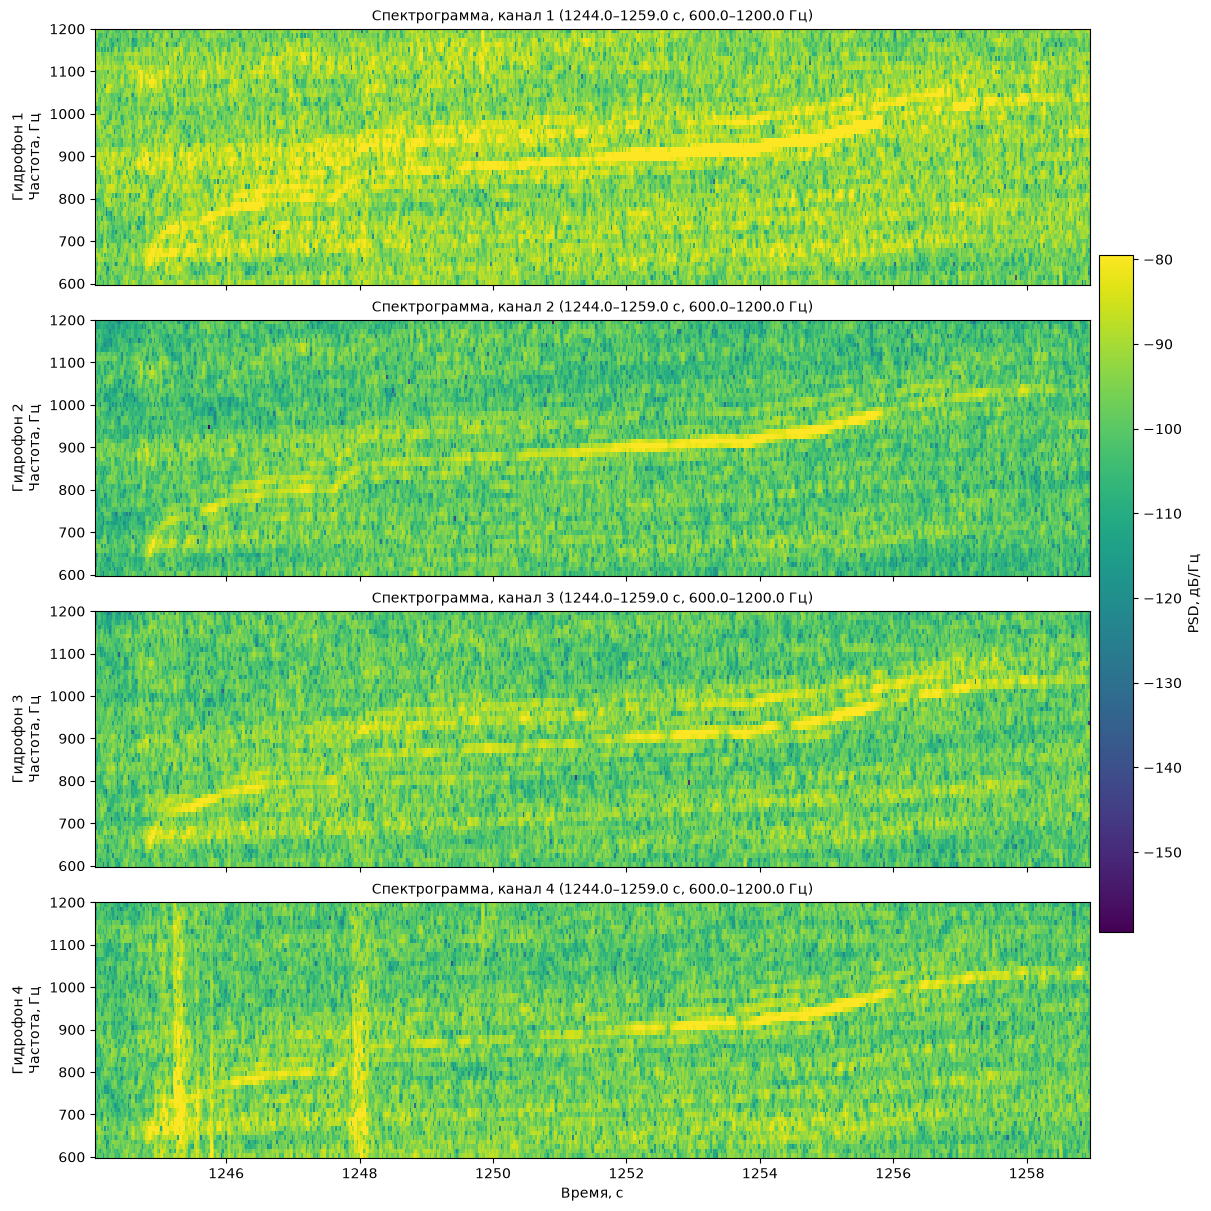

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# --- Параметры спектрограммы ---
SPEC_T_START = T_START          # начало, с (можно сузить, например 1244.0)
SPEC_T_END   = T_END            # конец, с
SPEC_F_MIN   = F_LOW            # нижняя частота отображения, Гц
SPEC_F_MAX   = F_HIGH           # верхняя частота отображения, Гц

# Параметры окна STFT
NPERSEG   = 4096                # длина окна (сэмплов) 
NOVERLAP  = NPERSEG * 3 // 4    # перекрытие 75%
NFFT      = NPERSEG             # можно увеличить для интерполяции по частоте
WINDOW    = 'hann'              # тип окна
DB_RANGE  = 80                  # динамический диапазон отображения, дБ

# ------------------------------------------------------------

i0 = int(SPEC_T_START * fs)
i1 = int(SPEC_T_END   * fs)

spec_data = []
for ch in range(4):
    seg = signals[ch][i0:i1].astype(np.float64)
    f, t, Sxx = spectrogram(
        seg,
        fs=fs,
        window=WINDOW,
        nperseg=NPERSEG,
        noverlap=NOVERLAP,
        nfft=NFFT,
        detrend='constant',
        scaling='density',
        mode='psd',
    )
    # перевод в дБ (защита от log(0))
    Sxx_db = 10 * np.log10(Sxx + 1e-20)
    # сдвиг времени к абсолютному времени записи
    t_abs = t + SPEC_T_START
    spec_data.append((f, t_abs, Sxx_db))


fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, sharey=True,
                         constrained_layout=True)

vmin_global, vmax_global = None, None
# сначала найдём общий уровень для одинаковой цветовой шкалы
all_db = np.concatenate([S[(f >= SPEC_F_MIN) & (f <= SPEC_F_MAX)].ravel()
                         for (f, _, S) in spec_data])
vmax_global = np.percentile(all_db, 99)
vmin_global = vmax_global - DB_RANGE

for ch, (f, t_abs, Sxx_db) in enumerate(spec_data):
    ax = axes[ch]
    fmask = (f >= SPEC_F_MIN) & (f <= SPEC_F_MAX)
    mesh = ax.pcolormesh(
        t_abs, f[fmask], Sxx_db[fmask, :],
        shading='auto', cmap='viridis',
        vmin=vmin_global, vmax=vmax_global,
    )
    ax.set_ylabel(f'Гидрофон {ch+1}\nЧастота, Гц')
    ax.set_title(f'Спектрограмма, канал {ch+1} '
                 f'({SPEC_T_START}–{SPEC_T_END} с, {SPEC_F_MIN}–{SPEC_F_MAX} Гц)',
                 fontsize=10)
    ax.grid(False)

axes[-1].set_xlabel('Время, с')
cbar = fig.colorbar(mesh, ax=axes, shrink=0.6, pad=0.01)
cbar.set_label('PSD, дБ/Гц')
plt.show()